# Encrypted Traffic Classification — Implementation Sprint
Day 1: baseline (RF + XGBoost on CICIDS2017) · Day 2: cross-dataset drop + evasion test

Run cells top to bottom (VS Code Jupyter, local Python kernel — no Colab needed). Fill in the
`# TODO` spots. RF always runs on CPU; XGBoost auto-detects whether your GPU is actually usable
and falls back to CPU 'hist' otherwise (see the GPU-check cell in Step 4) — CPU is plenty fast for
this data size either way.

## 0. Setup

In [1]:
!pip -q install xgboost imbalanced-learn kaggle boto3 psutil --upgrade


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Local run (no Colab): everything is read/written relative to this folder instead of /content.
# VS Code's Jupyter extension sets the notebook's own folder as the working directory by default —
# this print lets you confirm that's actually true before the download cells run.
PROJECT_DIR = os.getcwd()
print("Working directory (data will be downloaded here):", PROJECT_DIR)

# Quick RAM sanity check — RF (n_estimators=200, max_depth=20) and holding two multi-million-row
# datasets in memory at once can use several GB. Close other apps if this comes back low.
import psutil
avail_gb = psutil.virtual_memory().available / 1e9
print(f"Available RAM right now: {avail_gb:.1f} GB")
if avail_gb < 6:
    print("WARNING: less than 6 GB free. Close other apps (browser tabs, etc.) before running "
          "the Day 1 Step 4 training cell and the Day 2 dataset loads to avoid MemoryError/swapping.")

Working directory (data will be downloaded here): c:\Users\ASUS\OneDrive\Desktop\Sem 7\Cybersecurity\Project
Available RAM right now: 6.3 GB


## Day 1 — Step 1: Get CICIDS2017

Two options.

**Option A — Kaggle (recommended for speed):** a `kaggle.json` API token already sits next to this
notebook, so the download cell below will just work. If it's missing/expired, get a new one from
kaggle.com/settings -> "Create New Token" and drop it in this folder.

**Option B — Official UNB source:** download `MachineLearningCSV.zip` from
https://www.unb.ca/cic/datasets/ids-2017.html and extract the CSVs into a `cicids2017` folder next
to this notebook, then skip to Step 2.

In [3]:
# Option A: Kaggle download (local/VS Code — no Colab upload dialog, no chmod/root paths)

# kaggle.json already sits next to this notebook. Point the kaggle CLI at this folder instead
# of copying it into ~/.kaggle — avoids the Linux-only cp/chmod commands from the Colab version.
os.environ['KAGGLE_CONFIG_DIR'] = PROJECT_DIR
kaggle_json = os.path.join(PROJECT_DIR, 'kaggle.json')
assert os.path.exists(kaggle_json), (
    f"kaggle.json not found at {kaggle_json} — get one from kaggle.com/settings -> "
    "'Create New Token' and drop it next to this notebook."
)

cicids2017_dir = os.path.join(PROJECT_DIR, 'cicids2017')
os.makedirs(cicids2017_dir, exist_ok=True)
already_have = [f for f in os.listdir(cicids2017_dir) if f.endswith('.csv')]

if already_have:
    print(f"Found {len(already_have)} CSVs already in {cicids2017_dir}, skipping download.")
else:
    !kaggle datasets download -d chethuhn/network-intrusion-dataset -p "{cicids2017_dir}" --unzip

Found 8 CSVs already in c:\Users\ASUS\OneDrive\Desktop\Sem 7\Cybersecurity\Project\cicids2017, skipping download.


In [4]:
import glob
csv_2017_paths = glob.glob(os.path.join(cicids2017_dir, '**', '*.csv'), recursive=True)
print(f"Found {len(csv_2017_paths)} CSV files")
csv_2017_paths

Found 8 CSV files


['c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Friday-WorkingHours-Morning.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Monday-WorkingHours.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Tuesday-WorkingHours.pcap_ISCX.csv',
 'c:\\Users\\ASUS\\OneDrive\\Desktop\\Sem 7\\Cybersecurity\\Project\\cicids2017\\Wednesday-

## Day 1 — Step 2: Load, clean, align labels

CICIDS2017 CSVs have leading/trailing whitespace in column names — classic gotcha, fix it immediately
or every downstream column lookup silently fails.

In [5]:
def load_and_concat(paths):
    dfs = []
    for p in paths:
        df = pd.read_csv(p, low_memory=False)
        df.columns = df.columns.str.strip()  # fix the leading-space gotcha
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)



In [6]:
df_2017 = load_and_concat(csv_2017_paths)
print(df_2017.shape)
df_2017['Label'].value_counts()

(2830743, 79)


Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [7]:
def clean_df(df, label_col='Label'):
    df = df.copy()
    # drop inf/-inf -> NaN, then drop NaN rows
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    before = len(df)
    df.dropna(inplace=True)
    print(f"Dropped {before - len(df)} rows with NaN/Inf ({(before-len(df))/before:.2%})")

    # downcast float64 -> float32: halves memory for the numeric columns, which matters with
    # ~16 GB RAM and two multi-million-row datasets alive at once during Day 2
    float_cols = df.select_dtypes('float64').columns
    df[float_cols] = df[float_cols].astype('float32')

    # binary label: BENIGN vs everything else. Case-insensitive on purpose — CICIDS2017 labels
    # benign flows "BENIGN" (all caps) but CICIDS2018 labels them "Benign" (title case). A plain
    # `!= 'BENIGN'` comparison only matches the 2017 spelling, so every 2018 row — including the
    # ~1.49M genuinely benign ones — silently got binary_label=1 until this was caught by a
    # Benign support=0 in the Day 2 classification_report.
    df['binary_label'] = (df[label_col].str.strip().str.casefold() != 'benign').astype(int)
    return df

df_2017 = clean_df(df_2017)
df_2017['binary_label'].value_counts(normalize=True)

Dropped 2867 rows with NaN/Inf (0.10%)


binary_label
0    0.803189
1    0.196811
Name: proportion, dtype: float64

## Day 1 — Step 3: Feature selection

Drop network-specific artifacts (this is the justification you need for the methodology section too —
these features let a model memorize *this network's* topology instead of learning generalizable
traffic behavior, which is exactly why naive models collapse cross-dataset).

In [8]:
DROP_COLS = [
    'Flow ID', 'Source IP', 'Src IP', 'Destination IP', 'Dst IP',
    'Source Port', 'Src Port', 'Destination Port', 'Dst Port',
    'Timestamp', 'Protocol',
    'Flow Duration',       # duration itself is often a network/session artifact — drop per methodology
    'Label', 'binary_label',
]

def get_feature_cols(df):
    return [c for c in df.columns if c not in DROP_COLS and df[c].dtype != 'object']

feature_cols_2017 = get_feature_cols(df_2017)
print(f"{len(feature_cols_2017)} feature columns")
feature_cols_2017[:15]

76 feature columns


['Total Fwd Packets',
 'Total Backward Packets',
 'Total Length of Fwd Packets',
 'Total Length of Bwd Packets',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean']

## Day 1 — Step 4: Baseline train (RF + XGBoost)

Uses a stratified split. Note: for the *real* deliverable, revisit this split before you trust the number —
CICIDS2017 has documented near-duplicate flows (Engelen et al. 2021) that inflate random-split accuracy.
A safer version: dedup identical flow rows before splitting. Flagged as `# TODO dedup` below — do this if you
have 20 spare minutes, since your "single-dataset eval" gap claim in the lit survey directly implies you
should NOT repeat that same flaw in your own baseline.

In [9]:
# Deduplicate identical flow rows before splitting (fixes known CICIDS2017 near-duplicate issue)
print(f"Rows before deduplication: {len(df_2017)}")
n_before = len(df_2017)
df_2017 = df_2017.drop_duplicates(subset=feature_cols_2017)
n_after = len(df_2017)
print(f"Rows after deduplication: {n_after}")
print(f"Duplicate rate: {(n_before - n_after) / n_before:.2%}")

X = df_2017[feature_cols_2017]
y = df_2017['binary_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype('float32')
X_test_scaled = scaler.transform(X_test).astype('float32')

print("Train class balance:", y_train.value_counts(normalize=True).to_dict())

Rows before deduplication: 2827876
Rows after deduplication: 2198705
Duplicate rate: 22.25%
Train class balance: {0: 0.8470321166322904, 1: 0.15296788336770964}


In [10]:
# Confirm the GPU is actually usable by XGBoost (not just present).
# nvidia-smi succeeding is NOT sufficient: it only proves the driver is installed. XGBoost's
# CUDA runtime is bundled in the pip wheel and needs a driver new enough for THAT CUDA version —
# on a laptop with an older driver this fails silently, XGBoost falls back to CPU per-batch, and
# you pay for slow host<->device copies without ever getting the speed benefit. So instead of
# trusting nvidia-smi, do a tiny real fit and see if it actually runs on cuda.
import subprocess

GPU_AVAILABLE = False
try:
    subprocess.check_output('nvidia-smi')
    _X = np.random.rand(200, 4).astype('float32')
    _y = (np.random.rand(200) > 0.5).astype(int)
    with warnings.catch_warnings():
        warnings.simplefilter('error')  # XGBoost's CPU-fallback message is a UserWarning — treat it as failure
        XGBClassifier(n_estimators=2, tree_method='hist', device='cuda').fit(_X, _y)
    GPU_AVAILABLE = True
    print("GPU detected and usable by XGBoost — using device='cuda' below")
except Exception as e:
    print(f"GPU not usable by XGBoost ({type(e).__name__}) — using CPU 'hist' method instead")
    print("  Common cause: NVIDIA driver too old for this xgboost wheel's bundled CUDA version "
          "(compare `nvidia-smi`'s reported CUDA Version to xgboost.build_info()['CUDA_VERSION']). "
          "CPU 'hist' is still fast for this data size, so this isn't a blocker.")

Exception ignored on calling ctypes callback function <function _log_callback at 0x00000208B1C198A0>:
Traceback (most recent call last):
  File "C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\xgboost\_c_api.py", line 63, in _log_callback
    warnings.warn(smsg, UserWarning, stacklevel=3)
Exception ignored on calling ctypes callback function <function _log_callback at 0x00000208B1C198A0>:
Traceback (most recent call last):
  File "C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\xgboost\_c_api.py", line 63, in _log_callback
    warnings.warn(smsg, UserWarning, stacklevel=3)


GPU detected and usable by XGBoost — using device='cuda' below


In [11]:
# Class-weighted models (no SMOTE — synthetic data isn't defensible for flow-based tabular features)
# Speed fixes applied: tree_method='hist' (+ GPU if available), reduced n_estimators, bounded depth

models = {
    'RandomForest': RandomForestClassifier(
        n_estimators=200, max_depth=20, n_jobs=-1,
        class_weight='balanced', random_state=RANDOM_STATE
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        tree_method='hist', device='cuda' if GPU_AVAILABLE else 'cpu',
        eval_metric='logloss',
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        random_state=RANDOM_STATE
    ),
}

In [12]:
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    f1 = f1_score(y_test, preds)
    results[name] = {'model': model, 'preds': preds, 'f1': f1}
    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds, target_names=['Benign', 'Malicious']))


=== RandomForest ===
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    372475
   Malicious       1.00      1.00      1.00     67266

    accuracy                           1.00    439741
   macro avg       1.00      1.00      1.00    439741
weighted avg       1.00      1.00      1.00    439741



C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\xgboost\training.py:200: UserWarning: [17:12:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\xgboost\training.py:200: UserWarning: [17:12:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



=== XGBoost ===
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    372475
   Malicious       0.99      1.00      1.00     67266

    accuracy                           1.00    439741
   macro avg       1.00      1.00      1.00    439741
weighted avg       1.00      1.00      1.00    439741



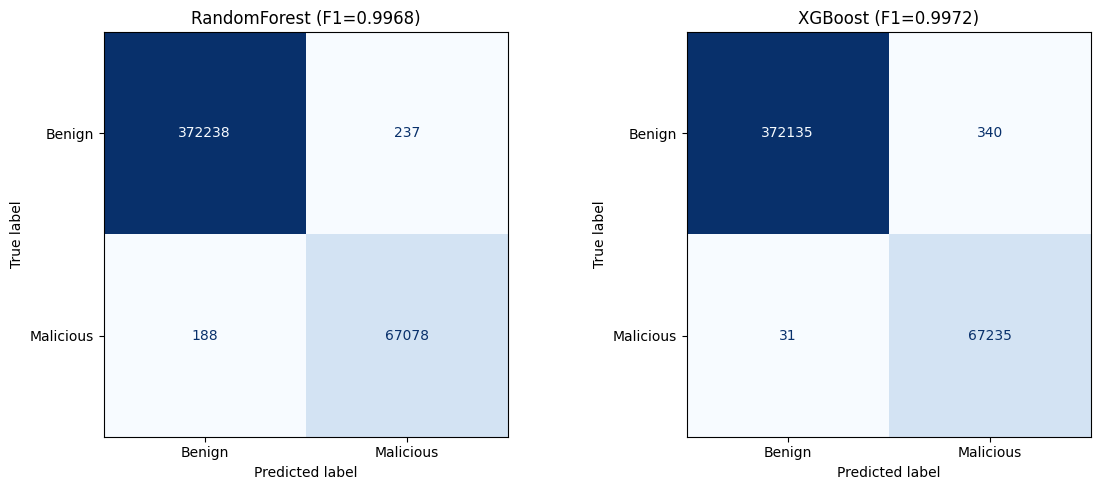

In [13]:
# Confusion matrices — one of your required plots
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
if len(models) == 1:
    axes = [axes]
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['preds'])
    ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malicious']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{name} (F1={r['f1']:.4f})")
plt.tight_layout()
plt.savefig('confusion_matrices_baseline.png', dpi=150)
plt.show()

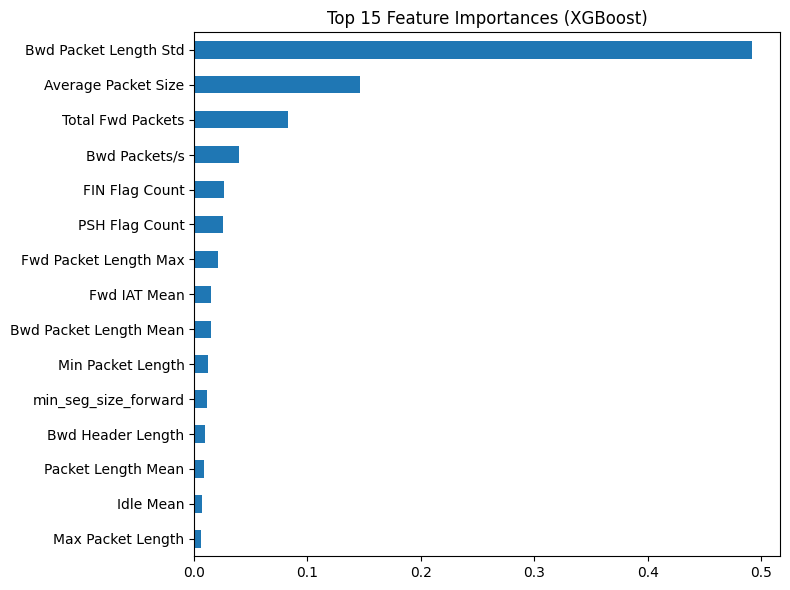

In [14]:
# Feature importance — another required plot
best_model_name = max(results, key=lambda k: results[k]['f1'])
best_model = results[best_model_name]['model']

importances = pd.Series(best_model.feature_importances_, index=feature_cols_2017).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title(f'Top 15 Feature Importances ({best_model_name})')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

**Checkpoint — Day 1 done when:** you have F1 scores for both models, two saved plots
(confusion matrices, feature importance), and ideally the dedup TODO addressed. This alone secures
partial marks per your teammate's plan — don't skip ahead until this runs clean.

## Day 2 — Step 1: Get CICIDS2018 (a couple of days' worth, not the whole week)

CICIDS2018's CSVs are hosted on public AWS S3 — no account or key needed with `--no-sign-request`.
Pulling 2 days (~600MB-1GB) is enough for a cross-dataset test; you don't need all ten.

In [15]:
# boto3 instead of the awscli CLI — avoids installing a Linux-oriented CLI tool with its own
# pinned botocore/s3transfer versions, and `--no-sign-request` maps to an UNSIGNED boto3 client.
import boto3
from botocore import UNSIGNED
from botocore.config import Config

cicids2018_dir = os.path.join(PROJECT_DIR, 'cicids2018')
os.makedirs(cicids2018_dir, exist_ok=True)

s3 = boto3.client('s3', region_name='us-east-1', config=Config(signature_version=UNSIGNED))
bucket = 'cse-cic-ids2018'
# Pick 1-2 specific days rather than syncing the whole folder (that's still several GB)
keys_to_get = [
    'Processed Traffic Data for ML Algorithms/Friday-16-02-2018_TrafficForML_CICFlowMeter.csv',
    'Processed Traffic Data for ML Algorithms/Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv',
]

for key in keys_to_get:
    dest = os.path.join(cicids2018_dir, os.path.basename(key))
    if os.path.exists(dest):
        print(f"Already downloaded: {dest}")
        continue
    print(f"Downloading {key} ...")
    s3.download_file(bucket, key, dest)
    print(f"  -> {dest}")

Already downloaded: c:\Users\ASUS\OneDrive\Desktop\Sem 7\Cybersecurity\Project\cicids2018\Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
Already downloaded: c:\Users\ASUS\OneDrive\Desktop\Sem 7\Cybersecurity\Project\cicids2018\Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv


In [16]:
csv_2018_paths = glob.glob(os.path.join(cicids2018_dir, '*.csv'))
df_2018 = load_and_concat(csv_2018_paths)
df_2018 = clean_df(df_2018, label_col='Label')
print(df_2018.shape)
df_2018['Label'].value_counts()

Dropped 5610 rows with NaN/Inf (0.27%)
(2091540, 81)


Label
Benign                      1489375
DoS attacks-Hulk             461912
DoS attacks-SlowHTTPTest     139890
Brute Force -Web                249
Brute Force -XSS                 79
SQL Injection                    34
Label                             1
Name: count, dtype: int64

## Day 2 — Step 2: Align columns between 2017 and 2018

This is the part most likely to eat your morning. 2018's CICFlowMeter output has different column
naming (no leading spaces, some renamed/reordered, a few present in one dataset but not the other).
Normalize names first, then take the intersection — check what gets dropped before trusting it.

In [17]:
def normalize_cols(cols):
    return [c.strip().lower().replace(' ', '_').replace('/', '_') for c in cols]

# Same measurement, different CICFlowMeter naming convention between dataset years (2018 abbreviates:
# pkt/packet, byts/bytes, cnt/count, tot/total, blk/bulk, seg/segment, ...). Built by pairing every
# entry in the two 'only in' lists below by meaning. Without this, ~30 features — including every
# packet-size and byte-count column — get silently dropped from the aligned set because they never
# match as plain strings, which also breaks the evasion simulator's packet-padding step downstream
# (it finds zero packet-size columns to perturb).
ALIAS_2018_TO_2017 = {
    'ack_flag_cnt': 'ack_flag_count',
    'fwd_act_data_pkts': 'act_data_pkt_fwd',
    'pkt_size_avg': 'average_packet_size',
    'bwd_seg_size_avg': 'avg_bwd_segment_size',
    'fwd_seg_size_avg': 'avg_fwd_segment_size',
    'bwd_blk_rate_avg': 'bwd_avg_bulk_rate',
    'bwd_byts_b_avg': 'bwd_avg_bytes_bulk',
    'bwd_pkts_b_avg': 'bwd_avg_packets_bulk',
    'bwd_header_len': 'bwd_header_length',
    'bwd_iat_tot': 'bwd_iat_total',
    'bwd_pkt_len_max': 'bwd_packet_length_max',
    'bwd_pkt_len_mean': 'bwd_packet_length_mean',
    'bwd_pkt_len_min': 'bwd_packet_length_min',
    'bwd_pkt_len_std': 'bwd_packet_length_std',
    'bwd_pkts_s': 'bwd_packets_s',
    'dst_port': 'destination_port',
    'ece_flag_cnt': 'ece_flag_count',
    'fin_flag_cnt': 'fin_flag_count',
    'flow_byts_s': 'flow_bytes_s',
    'flow_pkts_s': 'flow_packets_s',
    'fwd_blk_rate_avg': 'fwd_avg_bulk_rate',
    'fwd_byts_b_avg': 'fwd_avg_bytes_bulk',
    'fwd_pkts_b_avg': 'fwd_avg_packets_bulk',
    'fwd_header_len': 'fwd_header_length',
    'fwd_iat_tot': 'fwd_iat_total',
    'fwd_pkt_len_max': 'fwd_packet_length_max',
    'fwd_pkt_len_mean': 'fwd_packet_length_mean',
    'fwd_pkt_len_min': 'fwd_packet_length_min',
    'fwd_pkt_len_std': 'fwd_packet_length_std',
    'fwd_pkts_s': 'fwd_packets_s',
    'init_bwd_win_byts': 'init_win_bytes_backward',
    'init_fwd_win_byts': 'init_win_bytes_forward',
    'pkt_len_max': 'max_packet_length',
    'pkt_len_min': 'min_packet_length',
    'fwd_seg_size_min': 'min_seg_size_forward',
    'pkt_len_mean': 'packet_length_mean',
    'pkt_len_std': 'packet_length_std',
    'pkt_len_var': 'packet_length_variance',
    'psh_flag_cnt': 'psh_flag_count',
    'rst_flag_cnt': 'rst_flag_count',
    'subflow_bwd_byts': 'subflow_bwd_bytes',
    'subflow_bwd_pkts': 'subflow_bwd_packets',
    'subflow_fwd_byts': 'subflow_fwd_bytes',
    'subflow_fwd_pkts': 'subflow_fwd_packets',
    'syn_flag_cnt': 'syn_flag_count',
    'tot_bwd_pkts': 'total_backward_packets',
    'tot_fwd_pkts': 'total_fwd_packets',
    'totlen_bwd_pkts': 'total_length_of_bwd_packets',
    'totlen_fwd_pkts': 'total_length_of_fwd_packets',
    'urg_flag_cnt': 'urg_flag_count',
}
# Not aliased on purpose: 'fwd_header_length.1' (a duplicate column artifact only in the 2017 CSVs,
# no 2018 counterpart) and 2018's 'protocol'/'timestamp' (already excluded via DROP_COLS anyway).

norm_2017 = dict(zip(normalize_cols(df_2017.columns), df_2017.columns))
norm_2018_raw = dict(zip(normalize_cols(df_2018.columns), df_2018.columns))
norm_2018 = {ALIAS_2018_TO_2017.get(k, k): v for k, v in norm_2018_raw.items()}

common_norm = sorted(set(norm_2017) & set(norm_2018))
only_2017 = sorted(set(norm_2017) - set(norm_2018))
only_2018 = sorted(set(norm_2018) - set(norm_2017))

print(f"Common columns: {len(common_norm)} (was 29 before the alias map)")
print(f"\nOnly in 2017 ({len(only_2017)}):", only_2017)
print(f"\nOnly in 2018 ({len(only_2018)}):", only_2018)

Common columns: 79 (was 29 before the alias map)

Only in 2017 (1): ['fwd_header_length.1']

Only in 2018 (2): ['protocol', 'timestamp']


In [18]:
# Build the aligned feature set, excluding the artifact columns from before
common_features = [norm_2017[c] for c in common_norm
                    if c not in [x.strip().lower().replace(' ', '_') for x in DROP_COLS]]

# rename 2018 columns to match 2017 naming so both dataframes share identical column names
rename_2018 = {norm_2018[c]: norm_2017[c] for c in common_norm if c in norm_2018 and c in norm_2017}
df_2018_aligned = df_2018.rename(columns=rename_2018)

aligned_feature_cols = [c for c in common_features if c in df_2018_aligned.columns and c in df_2017.columns]
print(f"Final aligned feature count: {len(aligned_feature_cols)}")
aligned_feature_cols

Final aligned feature count: 75


['ACK Flag Count',
 'act_data_pkt_fwd',
 'Active Max',
 'Active Mean',
 'Active Min',
 'Active Std',
 'Average Packet Size',
 'Avg Bwd Segment Size',
 'Avg Fwd Segment Size',
 'Bwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd Header Length',
 'Bwd IAT Max',
 'Bwd IAT Mean',
 'Bwd IAT Min',
 'Bwd IAT Std',
 'Bwd IAT Total',
 'Bwd Packet Length Max',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Min',
 'Bwd Packet Length Std',
 'Bwd Packets/s',
 'Bwd PSH Flags',
 'Bwd URG Flags',
 'CWE Flag Count',
 'Down/Up Ratio',
 'ECE Flag Count',
 'FIN Flag Count',
 'Flow Bytes/s',
 'Flow IAT Max',
 'Flow IAT Mean',
 'Flow IAT Min',
 'Flow IAT Std',
 'Flow Packets/s',
 'Fwd Avg Bulk Rate',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Header Length',
 'Fwd IAT Max',
 'Fwd IAT Mean',
 'Fwd IAT Min',
 'Fwd IAT Std',
 'Fwd IAT Total',
 'Fwd Packet Length Max',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Min',
 'Fwd Packet Length Std',
 'Fwd Packets/s',
 'Fwd PSH Fla

## Day 2 — Step 3: Cross-dataset test — train on 2017, test on 2018 (headline result)

In [19]:
# Retrain on 2017 using ONLY the aligned feature set, so the comparison is apples-to-apples
X_2017_aligned = df_2017[aligned_feature_cols]
y_2017_aligned = df_2017['binary_label']

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_2017_aligned, y_2017_aligned, test_size=0.2, stratify=y_2017_aligned, random_state=RANDOM_STATE
)

scaler_aligned = StandardScaler()
X_train_a_scaled = scaler_aligned.fit_transform(X_train_a).astype('float32')
X_test_a_scaled = scaler_aligned.transform(X_test_a).astype('float32')

cross_model = RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight='balanced', random_state=RANDOM_STATE)
cross_model.fit(X_train_a_scaled, y_train_a)

# In-dataset (2017 test split) F1 — this is your baseline for comparison
in_dataset_preds = cross_model.predict(X_test_a_scaled)
in_dataset_f1 = f1_score(y_test_a, in_dataset_preds)
print(f"In-dataset (2017->2017) F1: {in_dataset_f1:.4f}")

In-dataset (2017->2017) F1: 0.9971


In [20]:
X_2018_aligned = df_2018_aligned[aligned_feature_cols].copy()
y_2018_aligned = df_2018_aligned['binary_label']

# Convert all feature columns to numeric, coercing errors to NaN
# This handles cases where non-numeric strings might have been introduced during data loading/processing
for col in aligned_feature_cols:
    if col in X_2018_aligned.columns: # Check if column exists, though it should
        X_2018_aligned[col] = pd.to_numeric(X_2018_aligned[col], errors='coerce')

# After coercing, drop any rows that now contain NaN values due to non-numeric data
# Align y_2018_aligned as well
original_len = len(X_2018_aligned)
nan_mask = X_2018_aligned.isna().any(axis=1)
X_2018_aligned = X_2018_aligned[~nan_mask]
y_2018_aligned = y_2018_aligned[~nan_mask]
print(f"Dropped {original_len - len(X_2018_aligned)} rows from X_2018_aligned due to non-numeric feature values after coercion.")

# Diagnostic: confirm the 2018 column order fed to predict() exactly matches the 2017 column
# order the model was fit on -- both by name AND by position, not just set membership. Both
# frames are indexed with the same aligned_feature_cols list variable (never independently
# rebuilt), so this is expected to print True; it's here to make that verifiable rather than
# assumed.
print("Feature order matches training:", list(X_2018_aligned.columns) == list(X_train_a.columns))
print("2018 first 5:", list(X_2018_aligned.columns)[:5])
print("2017 (train) first 5:", list(X_train_a.columns)[:5])

# Diagnostic: actual label/encoding sanity check before scoring. y_2017/y_2018 both come from the
# SAME clean_df() function (binary_label = str.strip().casefold() != 'benign'), so 0=Benign,
# 1=Malicious is guaranteed identical on both sides by construction, not by convention -- but
# print the real class balance being scored against rather than assume it.
print("y_train_a (2017) class balance:", y_train_a.value_counts().to_dict())
print("y_2018_aligned (2018 eval) class balance:", y_2018_aligned.value_counts().to_dict())

X_2018_scaled = scaler_aligned.transform(X_2018_aligned).astype('float32')
cross_preds = cross_model.predict(X_2018_scaled)
cross_f1 = f1_score(y_2018_aligned, cross_preds)

print(f"Cross-dataset (2017->2018) F1: {cross_f1:.4f}")
print(f"Drop: {in_dataset_f1 - cross_f1:.4f} ({(in_dataset_f1 - cross_f1) / in_dataset_f1:.1%} relative)")
print(classification_report(y_2018_aligned, cross_preds, target_names=['Benign', 'Malicious']))

Dropped 1 rows from X_2018_aligned due to non-numeric feature values after coercion.
Feature order matches training: True
2018 first 5: ['ACK Flag Count', 'act_data_pkt_fwd', 'Active Max', 'Active Mean', 'Active Min']
2017 (train) first 5: ['ACK Flag Count', 'act_data_pkt_fwd', 'Active Max', 'Active Mean', 'Active Min']
y_train_a (2017) class balance: {0: 1489899, 1: 269065}
y_2018_aligned (2018 eval) class balance: {0: 1489375, 1: 602164}
Cross-dataset (2017->2018) F1: 0.0023
Drop: 0.9948 (99.8% relative)
              precision    recall  f1-score   support

      Benign       0.71      1.00      0.83   1489375
   Malicious       0.81      0.00      0.00    602164

    accuracy                           0.71   2091539
   macro avg       0.76      0.50      0.42   2091539
weighted avg       0.74      0.71      0.59   2091539



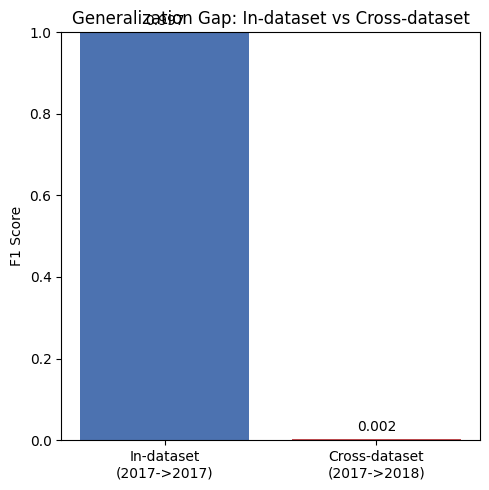

In [21]:
# Bar chart: in-dataset vs cross-dataset — required plot
plt.figure(figsize=(5, 5))
plt.bar(['In-dataset\n(2017->2017)', 'Cross-dataset\n(2017->2018)'], [in_dataset_f1, cross_f1],
        color=['#4C72B0', '#C44E52'])
plt.ylabel('F1 Score')
plt.ylim(0, 1)
plt.title('Generalization Gap: In-dataset vs Cross-dataset')
for i, v in enumerate([in_dataset_f1, cross_f1]):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.savefig('cross_dataset_gap.png', dpi=150)
plt.show()

## Day 2 — Step 4: Evasion simulator

Perturbs packet-length and inter-arrival-time (IAT) columns: padding (size increase) and jitter
(random delay). Column names below assume 2017 naming after your earlier normalization — print
`aligned_feature_cols` and adjust the substring matches if they don't line up.

In [22]:
def find_cols(cols, keywords):
    # normalize both sides (underscore-style keywords vs the space-separated 2017-style column
    # names in aligned_feature_cols) so e.g. keyword 'packet_length' matches 'Fwd Packet Length Max'
    def norm(s):
        return s.strip().lower().replace(' ', '_').replace('/', '_')
    return [c for c in cols if any(k.lower() in norm(c) for k in keywords)]

size_cols = find_cols(aligned_feature_cols, ['pkt_len', 'packet_length', 'pkt_size'])
iat_cols = find_cols(aligned_feature_cols, ['iat'])
print("Size columns:", size_cols)
print("IAT columns:", iat_cols)

Size columns: ['Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Min', 'Bwd Packet Length Std', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Min', 'Fwd Packet Length Std', 'Max Packet Length', 'Min Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance']
IAT columns: ['Bwd IAT Max', 'Bwd IAT Mean', 'Bwd IAT Min', 'Bwd IAT Std', 'Bwd IAT Total', 'Flow IAT Max', 'Flow IAT Mean', 'Flow IAT Min', 'Flow IAT Std', 'Fwd IAT Max', 'Fwd IAT Mean', 'Fwd IAT Min', 'Fwd IAT Std', 'Fwd IAT Total']


In [23]:
def evasion_perturb(X, size_cols, iat_cols, pad_frac=0.15, jitter_frac=0.20, seed=RANDOM_STATE):
    """
    Simulate an evader padding packet sizes and injecting timing jitter to slip past the classifier.
    X: dataframe of features (unscaled, original units).
    pad_frac: fractional increase applied to packet-size features (e.g. 0.15 = +15%).
    jitter_frac: fractional random noise applied to IAT features (uniform in [-jitter_frac, +jitter_frac]).
    """
    rng = np.random.default_rng(seed)
    X_evaded = X.copy()

    for col in size_cols:
        X_evaded[col] = X_evaded[col] * (1 + pad_frac)

    for col in iat_cols:
        noise = rng.uniform(-jitter_frac, jitter_frac, size=len(X_evaded))
        X_evaded[col] = X_evaded[col] * (1 + noise)
        X_evaded[col] = X_evaded[col].clip(lower=0)  # IAT can't go negative

    return X_evaded

# Apply evasion only to the malicious rows in the 2018 test set (that's who'd actually try to evade)
malicious_mask = y_2018_aligned == 1
X_2018_mal = X_2018_aligned[malicious_mask]
y_2018_mal = y_2018_aligned[malicious_mask]

X_2018_mal_evaded = evasion_perturb(X_2018_mal, size_cols, iat_cols)
X_2018_mal_evaded_scaled = scaler_aligned.transform(X_2018_mal_evaded)
X_2018_mal_scaled = scaler_aligned.transform(X_2018_mal)

preds_before = cross_model.predict(X_2018_mal_scaled)
preds_after = cross_model.predict(X_2018_mal_evaded_scaled)

detect_rate_before = preds_before.mean()  # fraction still correctly flagged malicious
detect_rate_after = preds_after.mean()

print(f"Detection rate before evasion: {detect_rate_before:.2%}")
print(f"Detection rate after evasion:  {detect_rate_after:.2%}")
print(f"Degradation: {detect_rate_before - detect_rate_after:.2%} points")

Detection rate before evasion: 0.12%
Detection rate after evasion:  0.00%
Degradation: 0.12% points


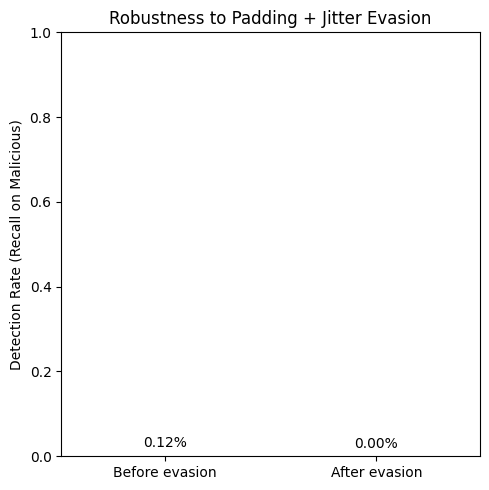

In [24]:
# Robustness comparison plot — required plot
plt.figure(figsize=(5, 5))
plt.bar(['Before evasion', 'After evasion'], [detect_rate_before, detect_rate_after],
        color=['#55A868', '#C44E52'])
plt.ylabel('Detection Rate (Recall on Malicious)')
plt.ylim(0, 1)
plt.title('Robustness to Padding + Jitter Evasion')
for i, v in enumerate([detect_rate_before, detect_rate_after]):
    plt.text(i, v + 0.02, f"{v:.2%}", ha='center')
plt.tight_layout()
plt.savefig('evasion_robustness.png', dpi=150)
plt.show()

## Stretch goals (only if time permits — priority is everything above)

Per your teammate's note: baseline + cross-dataset are the two that demonstrate real work.
Below are stubs for the two stretch items — partial code is fine to show if you run out of time.

In [25]:
# STUB: adversarial retraining loop
# Idea: augment the training set with evaded versions of malicious samples, retrain, re-measure.
X_train_evaded_mal = evasion_perturb(
    X_train_a[y_train_a == 1], size_cols, iat_cols
)
X_train_augmented = pd.concat([X_train_a, X_train_evaded_mal])
y_train_augmented = pd.concat([y_train_a, y_train_a[y_train_a == 1]])

# TODO: scale, SMOTE, retrain a fresh model on X_train_augmented/y_train_augmented,
# then re-run the evasion_perturb eval above against THIS model and compare detect_rate_after
# before vs after adversarial retraining -> that delta is your "robustness delta" metric.

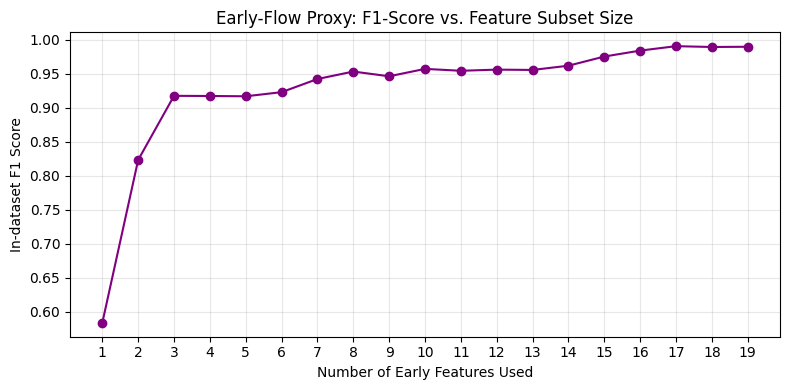

Max proxy F1 reached: 0.9908 with 19 features.


In [26]:
# Implementation: early-flow / partial-flow detection proxy

# Proxy: Forward-only and initial window features likely available 'early'
early_features = [
    'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max',
    'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std',
    'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
    'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Fwd Packets/s',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'min_seg_size_forward', 'act_data_pkt_fwd'
]

# Filter to only what is available in our aligned set
available_early = [c for c in early_features if c in aligned_feature_cols]

proxy_results = []
# Test performance as we increase the number of 'early' features considered
for i in range(1, len(available_early) + 1):
    subset = available_early[:i]

    # Use a simpler/faster RF for the loop
    proxy_clf = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1,
                                      class_weight='balanced', random_state=RANDOM_STATE)

    # Subset and scale
    X_sub_train = X_train_a[subset]
    X_sub_test = X_test_a[subset]
    scaler_p = StandardScaler()
    X_sub_train_scaled = scaler_p.fit_transform(X_sub_train)
    X_sub_test_scaled = scaler_p.transform(X_sub_test)

    proxy_clf.fit(X_sub_train_scaled, y_train_a)
    f1 = f1_score(y_test_a, proxy_clf.predict(X_sub_test_scaled))
    proxy_results.append(f1)

# Plot the curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(available_early) + 1), proxy_results, marker='o', linestyle='-', color='purple')
plt.title('Early-Flow Proxy: F1-Score vs. Feature Subset Size')
plt.xlabel('Number of Early Features Used')
plt.ylabel('In-dataset F1 Score')
plt.grid(True, alpha=0.3)
plt.xticks(range(1, len(available_early) + 1))
plt.tight_layout()
plt.savefig('early_flow_proxy.png', dpi=150)
plt.show()

print(f"Max proxy F1 reached: {max(proxy_results):.4f} with {len(available_early)} features.")